# Metrics Evaluation (Classification)

In [36]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)
import matplotlib.pyplot as plt 
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

In [ ]:
def calculate_metrics(y_true, y_pred, average='binary'):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=average, zero_division=0)
    rec = recall_score(y_true, y_pred, average=average, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=average, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)

    # Specificity 
    if average == 'binary':
        tn, fp,fn, tp = cm.ravel() # ravel -> mengubah array multi-dimensi menjadi 1 dimesi
        specificity = tn / (tn+tp) if (tn+fp) != 0 else 0 # langsung dari TN & FP
    
    else:
        # multiclass -> specificity per class lalu dirata-rata 
        specificity_list = []
        for i in range(len(cm)):
            tn = np.sum(cm) - (np.sum(cm[i, :]) + np.sum(cm[:, i]) - cm[i, i])
            fp = np.sum(cm[:, i]) - cm[i, i]
            specificity_list.append(tn / (tn + fp) if (tn + fp) != 0 else 0)

        specificity = np.mean(specificity_list) # dihitung per class dan dirata-rata
    return {
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        "Recall": round(rec, 4),
        "F1 Score": round(f1, 4),
        "Specificity": round(specificity, 4),
        "Confusion Matrix": cm
    }


### Binary Classification 

In [ ]:
X, y = make_classification(
    n_samples=10000,
    n_features=20,
    n_classes=2,
    random_state=42
)

model = LogisticRegression(max_iter=1000) # max_iter -> jumlah iterasi saat proses training/optimisasi model 

# Cross validation prediction 
y_pred_cv = cross_val_predict(model, X, y, cv=5)

metrics_cv = calculate_metrics(y, y_pred_cv, average='binary') # average = 'binary' karena binary class

# Train on full data 
model.fit(X, y)

LogisticRegression(max_iter=1000)

In [21]:
y_pred_train = model.predict(X)
metrics_train_bin = calculate_metrics(y, y_pred_train, average='binary')

In [22]:
for k, v in metrics_cv.items():
    print(f"{k}: \n{v}\n")

Accuracy: 
0.8883

Precision: 
0.8895

Recall: 
0.8865

F1 Score: 
0.888

Specificity: 
0.5015

Confusion Matrix: 
[[4455  550]
 [ 567 4428]]



In [23]:
for k, v in metrics_train_bin.items():
    print(f"{k}: \n{v}\n")

Accuracy: 
0.8892

Precision: 
0.8905

Recall: 
0.8873

F1 Score: 
0.8889

Specificity: 
0.5016

Confusion Matrix: 
[[4460  545]
 [ 563 4432]]



### Multiclass Classification 

In [ ]:
X, y = make_classification(
    n_samples=10000,
    n_features=20, 
    n_classes=3,
    n_informative=5,
    random_state=42
)

model = LogisticRegression(max_iter=1000)

# Cross validation prediction 
y_pred_cv = cross_val_predict(model, X, y, cv=5)

metrics_cv = calculate_metrics(y, y_pred_cv, average='macro') # average = 'macro' karena multiclass 

# Train on full data 
model.fit(X, y)

LogisticRegression(max_iter=1000)

In [25]:
y_pred = model.predict(X)
metrics_train = calculate_metrics(y, y_pred, average='macro')

for k, v in metrics_cv.items():
    print(f"{k}: \n{v}\n")

Accuracy: 
0.6641

Precision: 
0.6624

Recall: 
0.6638

F1 Score: 
0.6628

Specificity: 
0.8321

Confusion Matrix: 
[[2515  298  523]
 [ 273 2305  770]
 [ 566  929 1821]]



In [26]:
for k, v in metrics_train.items():
    print(f"{k}: \n{v}\n")

Accuracy: 
0.6675

Precision: 
0.6659

Recall: 
0.6672

F1 Score: 
0.6662

Specificity: 
0.8338

Confusion Matrix: 
[[2520  291  525]
 [ 265 2319  764]
 [ 564  916 1836]]



### Threshold Tuning

In [27]:
X, y = make_classification(
    n_samples=10000,
    n_features=20,
    n_classes=2,
    random_state=42
)

model = LogisticRegression(max_iter=1000) 

# Ambil probabilitas (bukan label)
y_proba = cross_val_predict(model, X, y, cv=5, method='predict_proba')

# Ambil probabilitas kelas positif 
y_scores = y_proba[:, 1]

# Coba beberapa threshold 
thresholds = [0.3, 0.5, 0.7]

for t in thresholds:
    y_pred_thresh = (y_scores >= t).astype(int)

    metrics = calculate_metrics(y, y_pred_thresh, average='binary')

    for k, v in metrics.items():
        print(f"{k}: \n{v}\n")

Accuracy: 
0.869

Precision: 
0.8215

Recall: 
0.9425

F1 Score: 
0.8779

Specificity: 
0.4582

Confusion Matrix: 
[[3982 1023]
 [ 287 4708]]

Accuracy: 
0.8883

Precision: 
0.8895

Recall: 
0.8865

F1 Score: 
0.888

Specificity: 
0.5015

Confusion Matrix: 
[[4455  550]
 [ 567 4428]]

Accuracy: 
0.8623

Precision: 
0.9279

Recall: 
0.7854

F1 Score: 
0.8507

Specificity: 
0.5451

Confusion Matrix: 
[[4700  305]
 [1072 3923]]



In [ ]:
"""
-> Recall tinggi berarti lebih banyak positif yang dapat dideteksi 
-> Precision tinggi maka model lebih yakin dengan hasil
"""

### Confusion Matrix

In [29]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)

    disp.plot()
    plt.title(title)
    plt.show()

In [30]:
X, y = make_classification(
    n_samples=10000,
    n_features=20,
    n_classes=2,
    random_state=42
)

model = LogisticRegression(max_iter=1000) # max_iter -> jumlah iterasi saat proses training/optimisasi model 

# Cross validation prediction 
y_pred_cv = cross_val_predict(model, X, y, cv=5)

metrics_cv = calculate_metrics(y, y_pred_cv, average='binary') # average = 'binary' karena binary class

# Train on full data 
model.fit(X, y)

LogisticRegression(max_iter=1000)

In [31]:
y_pred_train = model.predict(X)
metrics_train_bin = calculate_metrics(y, y_pred_train, average='binary')

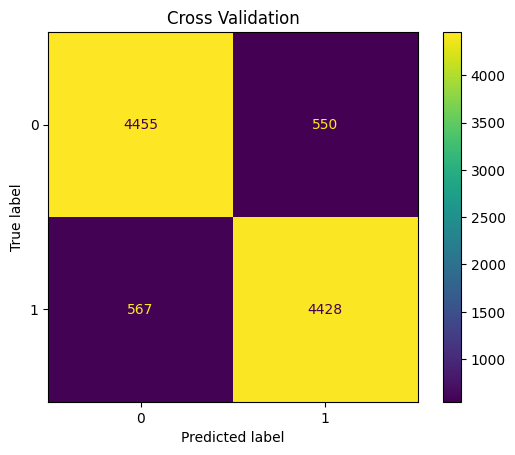

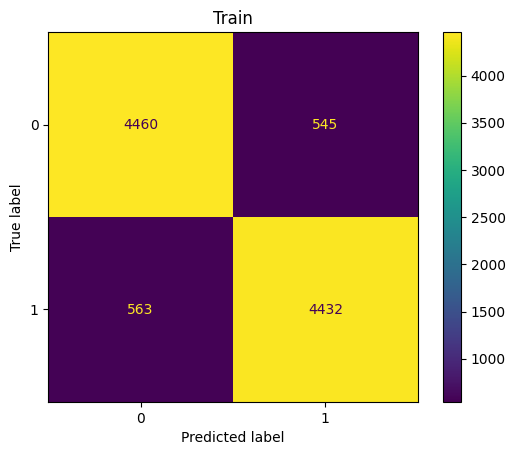

In [32]:
plot_confusion(y, y_pred_cv, 'Cross Validation')
plot_confusion(y, y_pred_train, 'Train')

In [33]:
X, y = make_classification(
    n_samples=10000,
    n_features=20, 
    n_classes=3,
    n_informative=5,
    random_state=42
)

model = LogisticRegression(max_iter=1000)

# Cross validation prediction 
y_pred_cv = cross_val_predict(model, X, y, cv=5)

metrics_cv = calculate_metrics(y, y_pred_cv, average='macro') # average = 'macro' karena multiclass 

# Train on full data 
model.fit(X, y)

LogisticRegression(max_iter=1000)

In [34]:
y_pred = model.predict(X)
metrics_train = calculate_metrics(y, y_pred, average='macro')

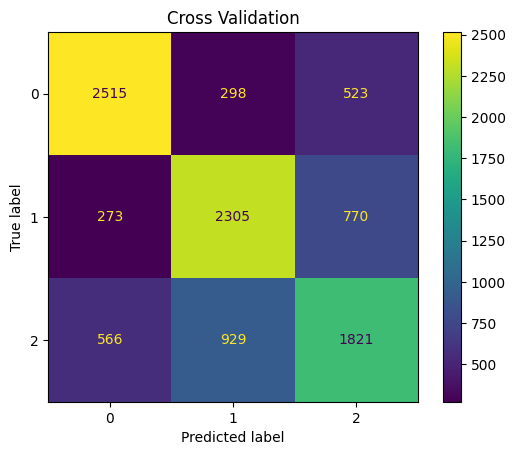

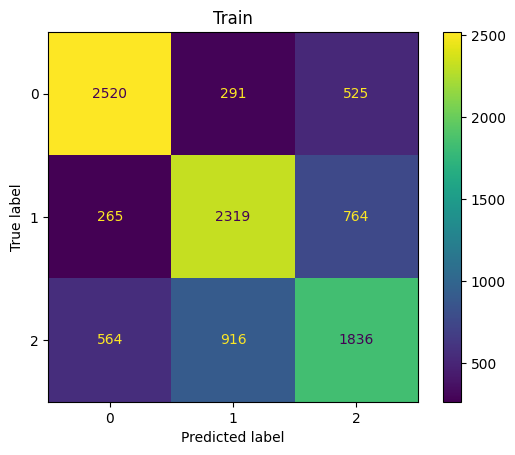

In [35]:
plot_confusion(y, y_pred_cv, 'Cross Validation')
plot_confusion(y, y_pred, 'Train')

In [ ]:
""" 
|          | Pred 0 | Pred 1 |
| -------- | ------ | ------ |
| Actual 0 | TN     | FP     |
| Actual 1 | FN     | TP     |

➡️ Fokus:
- FP tinggi → masalah di precision
- FN tinggi → masalah di recall

Multiclass:
- Diagonal = benar
- Selain diagonal = salah

➡️ Bisa lihat:
- Kelas mana sering ketukar
"""

### Threshold Optimization

In [ ]:
""" 
Apa itu Threshold?
    Threshold adalah batas nilai probabilitas untuk menentukan kelas

🔥 Hubungan dengan Metric
| Threshold | Precision | Recall |
| --------- | --------- | ------ |
| Rendah    | Turun     | Naik   |
| Tinggi    | Naik      | Turun  |

"""

In [37]:
X, y = make_classification(
    n_samples=10000,
    n_features=20,
    n_classes=2,
    random_state=42
)

model = LogisticRegression(max_iter=1000) # max_iter -> jumlah iterasi saat proses training/optimisasi model 

# Cross validation prediction 
y_pred_cv = cross_val_predict(model, X, y, cv=5)

metrics_cv = calculate_metrics(y, y_pred_cv, average='binary') # average = 'binary' karena binary class

# Train on full data 
model.fit(X, y)

LogisticRegression(max_iter=1000)

In [38]:
y_pred_train = model.predict(X)
metrics_train_bin = calculate_metrics(y, y_pred_train, average='binary')

In [39]:
y_pred_train = model.predict(X)
metrics_train_bin = calculate_metrics(y, y_pred_train, average='binary')

In [40]:
from sklearn.metrics import precision_recall_curve

# Ambil probabilitas dari CV
y_proba = cross_val_predict(model, X, y, cv=5, method='predict_proba')
y_scores = y_proba[:, 1]

# Hitung precision, recall, threshold
precisions, recalls, thresholds = precision_recall_curve(y, y_scores)

# Hitung F1 score untuk tiap threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)

# Cari threshold terbaik
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Best Threshold:", round(best_threshold, 4))
print("Best F1 Score:", round(f1_scores[best_idx], 4))
print("Precision at Best:", round(precisions[best_idx], 4))
print("Recall at Best:", round(recalls[best_idx], 4))

Best Threshold: 0.4168
Best F1 Score: 0.8918
Precision at Best: 0.8697
Recall at Best: 0.9151


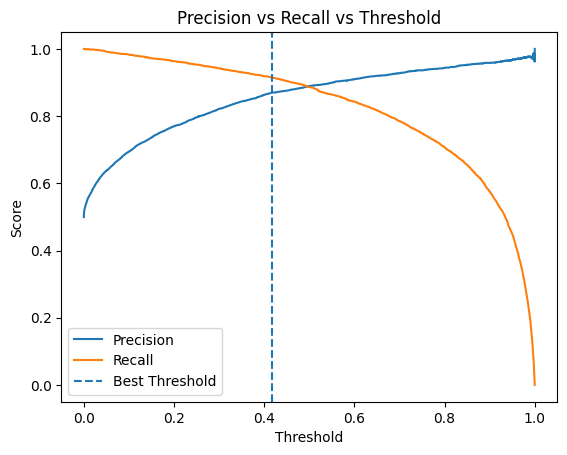

In [42]:
plt.figure()

plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")

plt.axvline(x=best_threshold, linestyle='--', label="Best Threshold")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall vs Threshold")
plt.legend()

plt.show()

### Dasar

In [ ]:
""" 
1. Confusion Matrix 

|                    | Pred Positif | Pred Negatif |
| ------------------ | ------------ | ------------ |
| **Actual Positif** | TP           | FN           |
| **Actual Negatif** | FP           | TN           |

- TP (True Positive) → benar prediksi positif
- TN (True Negative) → benar prediksi negatif
- FP (False Positive) → salah, harusnya negatif tapi diprediksi positif
- FN (False Negative) → salah, harusnya positif tapi diprediksi negatif

Positif (Positive Class) -> spam
➝ kelas yang jadi fokus utama / target
Negatif (Negative Class) -> bukan spam
➝ kelas selain itu (kebalikan dari positif)

2. Singkatan-Singkatan Penting 
- TPR (True Positive Rate) = Recall
➡️ Artinya:
- Dari semua yang benar-benar positif, berapa yang berhasil ditangkap?

- FPR (False Positive Rate)
➡️ Artinya:
- Dari semua yang sebenarnya negatif, berapa yang salah dianggap positif?

- TNR (True Negative Rate) = Specificity
➡️ Artinya:
- Seberapa baik model mengenali negatif?

- Precision
➡️ Artinya:
- Dari semua yang diprediksi positif, berapa yang benar?
📌 Fokus:
- Menghindari False Positive

- Recall (sama dengan TPR)
➡️ Fokus:
- Menghindari False Negative

- F1 Score
➡️ Artinya:
- Keseimbangan antara precision & recall

- Accuracy
➡️ Artinya:
- Seberapa banyak prediksi yang benar
⚠️ Bahaya:
- Menipu di data imbalanced

3. Hubungan Antar Metric 
- Precision vs Recall
| Naikkan Threshold | Turunkan Threshold |
| ----------------- | ------------------ |
| Precision ↑       | Recall ↑           |
| Recall ↓          | Precision ↓        |

- TPR vs FPR (ROC Curve)
TPR tinggi → bagus
FPR rendah → bagus

➡️ Model ideal:
TPR tinggi, FPR rendah
"""

### Multiclass Threshold

In [ ]:
"""
- Binary → kita pakai threshold (misal 0.5) untuk memutuskan kelas 0 atau 1
- Multiclass → biasanya pakai argmax (pilih probabilitas terbesar), jadi tidak perlu threshold tunggal

Tapi…
👉 threshold tetap bisa dipakai, hanya saja bentuknya:
- per kelas (one-vs-rest)
- atau untuk kebutuhan khusus (misalnya “reject option” kalau confidence rendah)

threshold:
A = 0.6
B = 0.4
C = 0.7

Logika:
- Jika prob kelas ≥ threshold → valid
- Kalau lebih dari satu lolos → ambil yang terbesar
- Kalau tidak ada → bisa dianggap “unknown”
"""

In [ ]:
from sklearn.datasets import load_iris 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier 
import numpy as np

iris = load_iris()
X = iris.data 
y = iris.target 

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)

y_pred_default = np.argmax(y_proba, axis=1)
print(y_pred_default)



[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]


In [ ]:
"""  
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1 0]

Data ke-1 → diprediksi kelas 1 (Versicolor)
Data ke-2 → kelas 0 (Setosa)
Data ke-3 → kelas 2 (Virginica)
dst ....
"""

In [4]:
thresholds = [0.6, 0.6, 0.6]

y_pred_custom = []

for probs in y_proba:
    valid_classes=[]

    for i, p in enumerate(probs):
        if p >= thresholds[i]:
            valid_classes.append((i, p))

    if len(valid_classes) == 0:
        # tidak ada yang lolos threshold 
        y_pred_custom.append(-1) #unknown 

    else:
        # pilih yang probabilitas besar
        best_class = sorted(valid_classes, key=lambda x : x[1], reverse=True)[0][0]
        y_pred_custom.append(best_class)

y_pred_custom = np.array(y_pred_custom)

print(y_pred_custom)

[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]


In [7]:
# Alternatif: One vs Rest Threshold

from sklearn.multiclass import OneVsRestClassifier 
from sklearn.linear_model import LogisticRegression 

model = OneVsRestClassifier(LogisticRegression())
model.fit(X_train, y_train)

OneVsRestClassifier(estimator=LogisticRegression())

In [ ]:
y_proba = model.predict_proba(X_test)

thresholds = [0.5, 0.5, 0.5] # kamu menetapkan batas minimum probabilitas agar suatu kelas dianggap “cukup yakin”

y_pred = (y_proba >= thresholds).astype(int)
print(y_pred)

[[0 1 0]
 [1 0 0]
 [0 0 1]
 [0 1 0]
 [0 1 0]
 [1 0 0]
 [0 1 0]
 [0 0 1]
 [0 1 0]
 [0 1 0]
 [0 0 1]
 [1 0 0]
 [1 0 0]
 [1 0 0]
 [1 0 0]
 [0 0 1]
 [0 0 1]
 [0 1 0]
 [0 1 0]
 [0 0 1]
 [1 0 0]
 [0 0 1]
 [1 0 0]
 [0 0 1]
 [0 0 1]
 [0 0 1]
 [0 0 1]
 [0 0 1]
 [1 0 0]
 [1 0 0]
 [1 0 0]
 [1 0 0]
 [0 1 0]
 [1 0 0]
 [1 0 0]
 [0 0 1]
 [0 1 0]
 [1 0 0]]


In [ ]:
"""  
Outputnya bisa jadi multi-label, contoh:

[1, 0, 1]  → kelas 0 dan 2 aktif
"""

### ROC dan AUC

In [ ]:
"""
1. Intuisi ROC dulu (biar nggak hafalan)
ROC = Receiver Operating Characteristic

👉 Intinya:
grafik yang menunjukkan performa model di berbagai threshold

🎯 Sumbu ROC
- X-axis → FPR (False Positive Rate)
- Y-axis → TPR (True Positive Rate = Recall)

🔢 Rumus penting
✅ Recall / TPR
    TPR = TP / (TP + FN)
👉 dari semua yang benar-benar positif, berapa yang berhasil ditangkap

❌ FPR
    FPR = FP / (FP + TN)
👉 dari semua yang sebenarnya negatif, berapa yang salah diprediksi positif

✅ Specificity
    Specificity = TN / (TN + FP)
👉 hubungan:
    FPR = 1 - Specificity

2. ROC itu sebenarnya apa?
Bayangkan kamu ubah threshold dari:
    0 → 1

Setiap threshold:
- menghasilkan nilai TPR & FPR
- jadi 1 titik di grafik
👉 kumpulan titik itu = ROC curve

🎯 3. AUC itu apa?
AUC = Area Under Curve
👉 luas di bawah kurva ROC

Interpretasi:
1.0 → model sempurna 🔥
0.5 → random (tebak-tebakan)
< 0.5 → model jelek
"""

In [9]:
from sklearn.datasets import load_breast_cancer 
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import roc_curve, auc 
import matplotlib.pyplot as plt 

data = load_breast_cancer()
X = data.data 
y = data.target 

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)



RandomForestClassifier()

In [10]:
y_proba = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_proba)

roc_auc = auc(fpr, tpr)

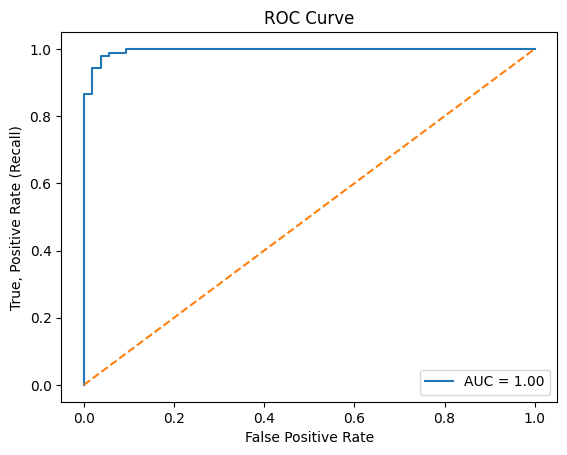

In [11]:
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel('True, Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [ ]:
"""  
6. Cara baca grafiknya
🔥 Model bagus:
- kurva naik cepat ke atas
- dekat kiri atas

❌ Model jelek:
- dekat garis diagonal

8. ROC vs Precision-Recall Curve
ROC bagus kalau:
- data balance
PR Curve lebih bagus kalau:
- data imbalance

9. Contoh efek threshold
Misalnya:
| Threshold | TPR (Recall) | FPR           |
| --------- | ------------ | ------------- |
| 0.9       | rendah       | sangat rendah |
| 0.5       | sedang       | sedang        |
| 0.1       | tinggi       | tinggi        |

makin rendah threshold:
- recall naik
- false positive juga naik

10. Insight penting
ROC menjawab:
👉 “seberapa baik model memisahkan kelas?”

Bukan:
👉 “seberapa akurat prediksi positif?”
"""